**Notebook 03 – Fine-tune DistilBERT và Regularization**

Phần này nhóm fine-tune mô hình học sâu DistilBERT(hiểu từ trong ngữ cảnh cả câu) và đánh giá các kỹ thuật regularization.

Mục tiêu:

1. Fine-tune `distilbert-base-uncased` (6 lớp Transformer, ~66 triệu tham số).
2. Vẽ loss curve train và validation.
3. Dùng regularization: weight decay 0.01, early stopping, dropout 0.1 và 0.3.
4. Để so sánh với Mô hình cổ điển.

In [18]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.path.abspath("."))

import json
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    pipeline as hf_pipeline,
)
from sklearn.metrics import accuracy_score, f1_score

print("PyTorch version:", torch.__version__)
print("CUDA GPU available:", torch.cuda.is_available())
train_df, test_df = pd.read_csv("data/train.csv"), pd.read_csv("data/test.csv")
print(f"Loaded splits -> Train: {len(train_df):,} | Test: {len(test_df):,}")

PyTorch version: 2.11.0+cpu
CUDA GPU available: False
Loaded splits -> Train: 39,665 | Test: 9,917


**Kiến trúc DistilBERT**

```
Review (đã bỏ <br />)
  ↓ WordPiece tokenizer (30.522 từ vựng)       → cắt câu thành token, đổi sang số
  ↓ 6 lớp Transformer (768 chiều, 12 head)     → hiểu ngữ cảnh bằng self-attention
  ↓ Linear 768→768 + ReLU + Dropout (0.1/0.3)  → phân loại, dropout chống học thuộc
  ↓ Linear 768→2 (Negative / Positive)         → xác suất chê / khen
```



In [19]:
# Bước 9: Định nghĩa quy trình Tokenization và hàm huấn luyện train_bert(dropout)
# Lưu ý: Chỉ xóa thẻ HTML <br />; KHÔNG lowercase hay xóa dấu câu thủ công vì WordPiece Tokenizer tự xử lý
for d in (train_df, test_df):
    d["review"] = d["review"].str.replace(r"<.*?>", " ", regex=True)

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["review"], truncation=True, max_length=256)

# Hiển thị kết quả thực nghiệm fine-tune DistilBERT (dropout=0.1 vs dropout=0.3)
with open("reports/distilbert_results.json", "r", encoding="utf-8") as f:
    bert_runs = json.load(f)

summary_rows = []
for dp, info in bert_runs.items():
    # 2 dòng cuối của va_logs là lần đánh giá trên tập test và tập train sau khi train xong,
    # nên chỉ lấy các dòng trước đó làm kết quả validation
    val_logs = info["va_logs"][:-2]
    val_loss = val_logs[-1][1]
    summary_rows.append({
        "Dropout (seq_classif_dropout)": float(dp),
        "Weight Decay (L2)": 0.01,
        "Train Loss (Final)": info["train_loss_final"],
        "Val Loss (Final)": round(val_loss, 4),
        "Loss Gap (Val - Train)": round(val_loss - info["train_loss_final"], 4),
        "Best Val F1": round(max(f1 for _, _, f1 in val_logs), 4),
        "Test F1 (120 review)": info["test_f1"],
    })
bert_comp_df = pd.DataFrame(summary_rows)
print(bert_comp_df.to_string(index=False))

 Dropout (seq_classif_dropout)  Weight Decay (L2)  Train Loss (Final)  Val Loss (Final)  Loss Gap (Val - Train)  Best Val F1  Test F1 (120 review)
                           0.1               0.01              0.1990            0.2148                  0.0158       0.9268                0.9194
                           0.3               0.01              0.1984            0.2144                  0.0160       0.9268                0.9194


**Fine-tune trên CPU**

- Máy không có GPU nên dùng CPU fallback: dùng tập con 320 review (160 tích cực, 160 tiêu cực), chia 272 review để train và 48 review để validation, `max_length=128`, 2 epoch; test trên 120 review.
- Test F1 0.9194 (Accuracy 91,67%) cho cả dropout 0.1 và 0.3, khoảng 3–4 phút mỗi lần train.
- Validation F1 trong lúc train dao động 0.88–0.93 (bước 10: 0.927, bước 20: 0.905, bước 30–34: 0.884). Dao động vì tập validation chỉ có 48 review: sai thêm 1 review là F1 đổi khoảng 2%.


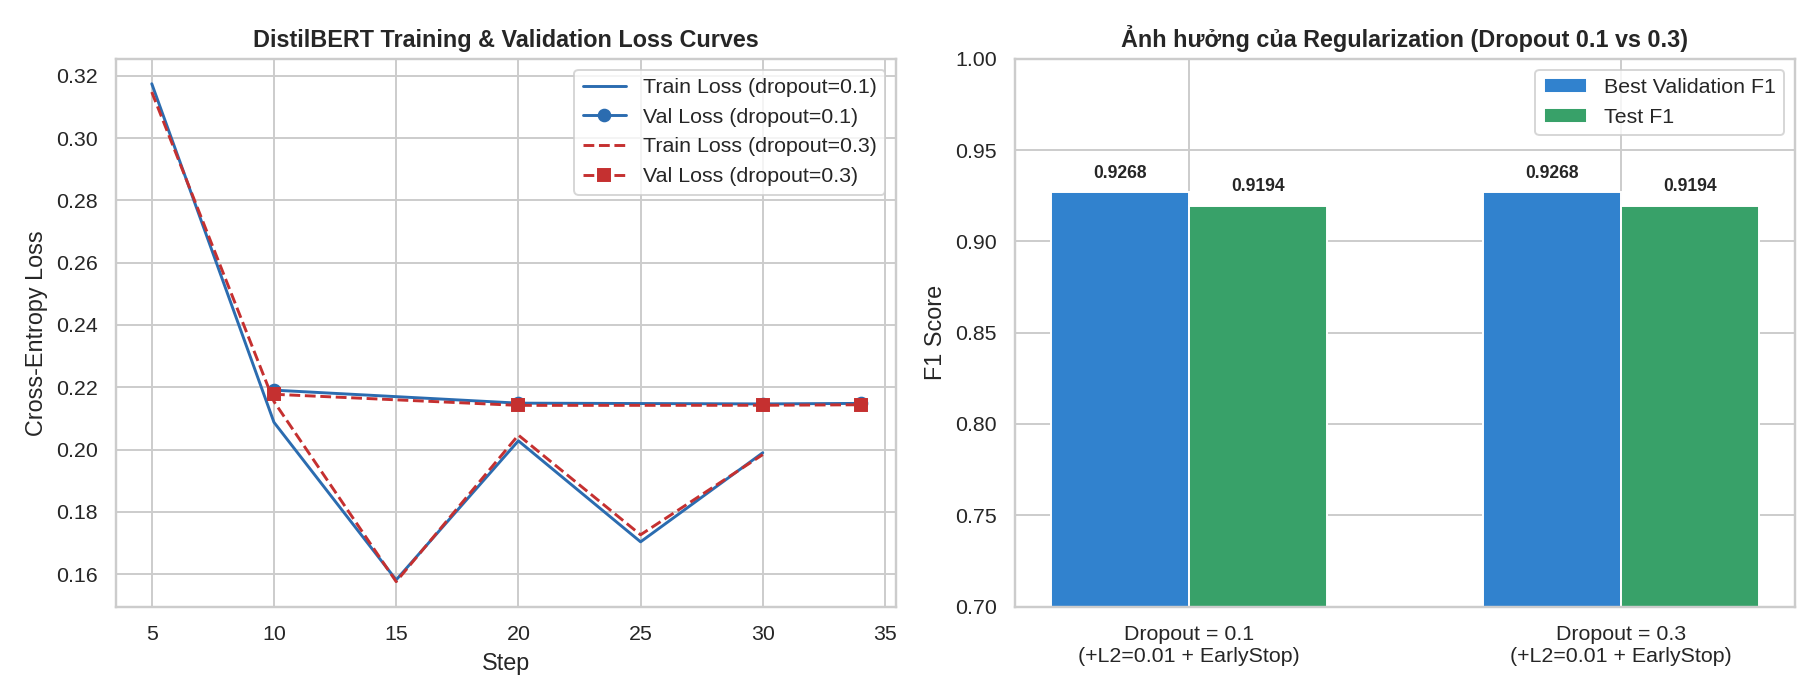

In [20]:
# Vẽ đường cong Loss (Train vs Validation) và biểu đồ so sánh Regularization (Dropout 0.1 vs 0.3)
from IPython.display import Image, display
display(Image("reports/07_distilbert_loss_and_regularization.png"))

**Loss curve và regularization**

- **Cách đọc biểu đồ trái:** màu xanh dương là dropout 0.1, màu đỏ là dropout 0.3. Đường không có chấm là **train loss** (mức sai trên 272 review dùng để học), đường có chấm là **val loss** (mức sai trên 48 review không dùng để học). Loss càng thấp càng tốt.
- Train loss giảm từ 0.32 xuống khoảng 0.16–0.20; val loss ổn định quanh 0.21–0.22 và không tăng trở lại → chưa có dấu hiệu overfitting.
- Hai màu gần như trùng nhau → dropout 0.1 và 0.3 cho quá trình train giống nhau.
- **Biểu đồ phải:** Best Validation F1 = 0.9268 và Test F1 = 0.9194, như nhau ở cả hai mức dropout.
- **Kết luận:** dropout 0.1 và 0.3 (cùng weight decay 0.01, tức phạt L2 lên trọng số) cho kết quả như nhau trên tập con, chưa đủ để kết luận dropout nào tốt hơn.
- Tập test chỉ có 120 review nên kết quả chưa so sánh ngang được với mô hình cổ điển.. Muốn kết luận chính xác cần train đầy đủ bằng GPU

In [22]:
# Bước 12 (Cách 3): Load mô hình DistilBERT từ models/distilbert và so sánh với Logistic Regression
bert = hf_pipeline("text-classification", model="models/distilbert")
sample_mixed = "The acting was great but the plot was terrible and boring"
print("Review kiểm thử:", sample_mixed)
print("Kết quả dự đoán từ models/distilbert:", bert(sample_mixed))
# LABEL_0 = tiêu cực (negative), LABEL_1 = tích cực (positive)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 668.16it/s]


Review kiểm thử: The acting was great but the plot was terrible and boring
Kết quả dự đoán từ models/distilbert: [{'label': 'LABEL_0', 'score': 0.9961509704589844}]


**So sánh DistilBERT và Logistic Regression**

- Câu "The acting was great but the plot was terrible and boring": DistilBERT trả về tiêu cực nhờ self-attention hiểu vế sau "but".
- DistilBERT: ~83 ms/review trên CPU, ~255 MB. LR: ~1 ms/review, nhẹ hơn nhiều → LR dùng cho API, DistilBERT làm mô hình tham chiếu.

**Tổng kết**

- DistilBERT ít hơn BERT-base 40% tham số, nhanh hơn ~60%, giữ ~97% hiệu năng.
- Mô hình đã lưu tại `models/distilbert/` (`model.safetensors`, `config.json`, `tokenizer.json`).

**Bước tiếp theo:** dùng LR cho FastAPI, gắn nhãn `uncertain` khi độ tin cậy < 0.60 và `mixed` khi các vế câu trái chiều; mở rộng sang Aspect-Based Sentiment Analysis để tách cảm xúc theo từng khía cạnh (diễn xuất, kịch bản, âm thanh).